<a href="https://colab.research.google.com/github/marina-mr/meteo-python/blob/main/Practica_centros_alumnado_v02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Python en práctica: una red de centros deportivos
**MABA · Sesión 2 · Versión 02**

Trabajarás con **seis centros en Madrid, Barcelona y Valencia**, cuatro tipos de actividad y turnos de mañana y tarde. Cada centro ofrece tres tipos de actividad. Leerás archivos, consultarás Open-Meteo y unirás las fuentes para calcular y representar resultados.

El catálogo y la actividad son **datos sintéticos docentes**, preparados y completos. La meteorología es histórica y procede de Open-Meteo. Las coordenadas son referencias de cada ciudad, compartidas por sus dos centros; no corresponden a instalaciones reales. Las visitas cuentan asistencias a sesiones, no personas únicas.

## Cómo trabajar con las celdas
- Una celda de código **sin comentarios** está resuelta: ejecútala y observa su resultado.
- Si debes completar o cambiar código, encontrarás **`# MODIFICAR: ...`**, con la instrucción en mayúsculas. Cambia únicamente lo indicado. Los nombres exactos de variables y funciones aparecen en el enunciado; respeta sus minúsculas en Python.
- En las plantillas, sustituye los `None` o `pass`. Cuando esté resuelta la tarea, elimina también la línea `raise NotImplementedError(...)`, tal como indica su comentario. Esa línea señala una tarea pendiente.
- Las explicaciones y las preguntas están en las celdas de texto. Escribe tus respuestas donde aparece **Respuesta: …**.
- Ejecuta las celdas en orden. El notebook inicial tiene tareas pendientes; el completado debe poder ejecutarse entero.

La primera y la última respuesta son individuales y sin IA. Durante el desarrollo puedes consultar IA sobre fragmentos concretos; comprueba y explica las sugerencias que aceptes.

## Qué entregar
Notebook completado con salidas y respuestas, ZIP de resultados, enlace al repositorio y al commit final. El repositorio debe conservar una versión inicial y otra final del mismo notebook, las entradas y un README. Documenta dos decisiones de revisión con IA.

**Autores:** Juan Carlos y Marina **Repositorio:** https://github.com/marina-mr/meteo-python

## 0. Entradas y diagnóstico
Descomprime el paquete. Abre el notebook en Google Colab, guarda una copia en Drive y conecta el entorno. Cuando se solicite, selecciona `actividad.csv` y `centros.xlsx` de la carpeta `datos`.

| Archivo | Campos | Qué representan |
|---|---|---|
| actividad.csv | actividad_id | Identificador único de una sesión deportiva. |
| actividad.csv | centro_id, fecha | Centro y día de la sesión. La fecha es un texto año-mes-día. |
| actividad.csv | actividad, turno | Tenis, Atletismo, Yoga o Entrenamiento funcional; Mañana o Tarde. |
| actividad.csv | duracion_min | Duración de la sesión, en minutos. |
| actividad.csv | plazas, visitas | Capacidad de la sesión y asistencias registradas. |
| centros.xlsx, hoja centros | centro_id, nombre, ciudad | Una fila por centro. |
| centros.xlsx | latitud, longitud | Coordenadas de referencia de su ciudad. |
| Open-Meteo | time, temperature_2m_max/min, precipitation_sum | Día, temperaturas máxima/mínima (°C) y precipitación (mm). |

Hay 504 sesiones: 14 días × 6 centros × 3 actividades por centro × 2 turnos. Las fechas vienen ya preparadas en el mismo formato que la API y se usarán directamente en la unión.

### Diagnóstico individual, antes de usar IA
1. ¿Qué representa una fila de actividad y una del catálogo? ¿Qué campo las relaciona?
2. Si dos centros pertenecen a una ciudad, ¿cuántas consultas meteorológicas necesitas para esa ciudad?
3. Una sesión tiene 15 visitas y 20 plazas. ¿Cómo calcularías su porcentaje de ocupación?

**Respuesta:**


1.   Una fila de actividad representa una sesión deportiva concreta, mientras que una fila del catálogo contiene la información de un centro deportivo, como su nombre, ciudad y coordenadas. Ambas tablas se relacionan mediante el campo centro_id, que identifica cada centro.
2.   En este caso, solo necesitamos una consulta meteorológica para esa ciudad, ya que los dos centros van a compartir la misma información meteorológica.
3.   Para calcular el porcentaje de ocupación, habría que dividir el número de visitas entre el número de plazas y luego multiplicarlos por 100. Luego, con estos datos sería: $(15/20)$⋅$100 = 75\%$ de ocupación.



### Preparar bibliotecas
Importamos las herramientas de lectura, peticiones, cálculo y gráficos. `Path` permite construir rutas de archivos.

In [2]:
from pathlib import Path
import json
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

### Cargar las entradas en Colab
Selecciona los dos archivos de datos a la vez. Repite la carga si inicias un entorno nuevo.

In [3]:
from google.colab import files

archivos_subidos = files.upload()

Saving actividad.csv to actividad.csv
Saving centros.xlsx to centros.xlsx


In [4]:
DATOS = Path('.')
SALIDAS = Path('salidas')
SALIDAS.mkdir(exist_ok=True)

### Versión inicial en GitHub
Crea un repositorio `practica-centros-python` con README. Desde Colab, usa **Archivo > Guardar una copia en GitHub**. Selecciona la rama y la ruta `practica_centros.ipynb`, con mensaje `Añade punto de partida de la práctica`. Conserva ese nombre y esa ruta para guardar la versión final.

Puedes usar un repositorio privado. No necesitas GitHub Desktop ni hacer push desde el ordenador.

## 1. Funciones y bucles
### R1. Revisar una función
Este fragmento muestra el porcentaje, pero no lo devuelve para reutilizarlo:
```python
def calcular_ocupacion(visitas, plazas):
    print(visitas / plazas * 100)
```
Completa la función con `return`. Prueba `calcular_ocupacion(15, 20)`: debe devolver 75.0. Las plazas de este ejercicio son siempre positivas.

In [5]:
def calcular_ocupacion(visitas, plazas):
    return visitas / plazas * 100

print(calcular_ocupacion(15, 20))

75.0


### T1. Clasificar la ocupación
Define `clasificar_ocupacion(porcentaje)` con `if`, `elif`, `else` y `return`. Devuelve `Baja` si el porcentaje es menor que 50, `Media` si es menor que 80 y `Alta` en el resto de casos. Son categorías descriptivas del ejercicio. Comprueba los valores 40, 50 y 80.

In [6]:
def clasificar_ocupacion(porcentaje):
    if porcentaje < 50:
        return 'Baja'
    elif porcentaje < 80:
        return 'Media'
    else:
        return 'Alta'

print(clasificar_ocupacion(40))
print(clasificar_ocupacion(50))
print(clasificar_ocupacion(80))


Baja
Media
Alta


### R2. Revisar un while
Lee este fragmento sin ejecutarlo: le falta avanzar el índice.
```python
turnos = ['Mañana', 'Tarde']
indice = 0
while indice < len(turnos):
    print(turnos[indice])
```
Completa el bucle para que muestre cada turno una sola vez y termine. **Respuesta:** ¿qué ocurre si el índice nunca cambia? Si el índice no se actualiza en cada iteración del bucle, estaríamos ejecutando un bucle infinito y siempre imprimiría `turnos[0]=Mañana`.

In [7]:
turnos = ['Mañana', 'Tarde']
indice = 0
while indice < len(turnos):
    print(turnos[indice])
    indice += 1  # Actualizamos el índice

Mañana
Tarde


## 2. Leer archivos y utilizar estructuras
### T2. CSV y Excel
Lee `actividad.csv` con `pd.read_csv` y `centros.xlsx` con `pd.read_excel`, indicando `sheet_name='centros'`. Usa las rutas `DATOS / 'actividad.csv'` y `DATOS / 'centros.xlsx'`.

In [8]:
actividad_original = pd.read_csv(DATOS / 'actividad.csv')
centros = pd.read_excel(DATOS / 'centros.xlsx', sheet_name='centros')


In [9]:
print(actividad_original.shape)
print(actividad_original.columns)
print(actividad_original.dtypes)
actividad_original.head()

(504, 8)
Index(['actividad_id', 'centro_id', 'fecha', 'actividad', 'turno',
       'duracion_min', 'plazas', 'visitas'],
      dtype='object')
actividad_id    object
centro_id       object
fecha           object
actividad       object
turno           object
duracion_min     int64
plazas           int64
visitas          int64
dtype: object


,actividad_id,centro_id,fecha,actividad,turno,duracion_min,plazas,visitas
0,ACT0001,C01,2026-09-01,Atletismo,Mañana,75,32,22
1,ACT0002,C01,2026-09-01,Atletismo,Tarde,75,32,20
2,ACT0003,C01,2026-09-01,Yoga,Mañana,45,24,14
3,ACT0004,C01,2026-09-01,Yoga,Tarde,45,24,19
4,ACT0005,C01,2026-09-01,Entrenamiento funcional,Mañana,60,20,10


In [10]:
actividad_original.info()
centros

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   actividad_id  504 non-null    object
 1   centro_id     504 non-null    object
 2   fecha         504 non-null    object
 3   actividad     504 non-null    object
 4   turno         504 non-null    object
 5   duracion_min  504 non-null    int64 
 6   plazas        504 non-null    int64 
 7   visitas       504 non-null    int64 
dtypes: int64(3), object(5)
memory usage: 31.6+ KB


,centro_id,nombre,ciudad,latitud,longitud
0,C01,Centro Retiro,Madrid,40.4168,-3.7038
1,C02,Centro Alameda,Madrid,40.4168,-3.7038
2,C03,Centro Litoral,Barcelona,41.3851,2.1734
3,C04,Centro Montjuïc,Barcelona,41.3851,2.1734
4,C05,Centro Turia,Valencia,39.4699,-0.3763
5,C06,Centro Malvarrosa,Valencia,39.4699,-0.3763


### Etiquetas y posiciones
Ejecuta los ejemplos. `loc` usa etiquetas y nombres de columnas; `iloc` usa posiciones. **Respuesta:** ¿qué devuelve cada celda?


*   La celda con `.loc` selecciona los datos mediante etiquetas de filas y nombres de columnas. En este caso, se selecciona de la fila con índice 0, los valores de las dos primeras columnas (`actividad_id` y `centro_id`). Por tanto, el resultado tiene que ser `ACT0001` y `C01`.
*   La celda con `.iloc` selecciona los datos mediante posiciones numéricas, comenzando desde 0. En este caso, se selecciona el valor de la primera fila y la segunda columna. Por tanto, el resultado tiene que ser `C01`.





In [11]:
actividad_original.loc[0, ['actividad_id', 'centro_id']]


,0
actividad_id,ACT0001
centro_id,C01


In [12]:
actividad_original.iloc[0, 1]

'C01'

### T3. Listas, diccionarios, tuplas y conjuntos
`to_dict('records')` produce una lista de diccionarios, uno por centro. Completa una comprensión para obtener sus ciudades. Después utiliza `set` para obtener las ciudades distintas. Guarda las coordenadas del primer centro en una tupla y desempaquétala en `latitud` y `longitud`.

**Respuesta:** ¿por qué la lista tiene seis elementos y el conjunto solo tres? Porque las listas sí que pueden incluir elementos repetidos, mientras que los conjuntos no. Más concretamente, en este ejemplo, en la lista hay 6 ciudades (Madrid, Madrid, Barcelona, Barcelona, Valencia, Valencia) mientras que en el conjunto aparecen solo 3 (Madrid, Barcelona, Valencia).

In [13]:
centros_lista = centros.to_dict('records')
centros_lista

[{'centro_id': 'C01',
  'nombre': 'Centro Retiro',
  'ciudad': 'Madrid',
  'latitud': 40.4168,
  'longitud': -3.7038},
 {'centro_id': 'C02',
  'nombre': 'Centro Alameda',
  'ciudad': 'Madrid',
  'latitud': 40.4168,
  'longitud': -3.7038},
 {'centro_id': 'C03',
  'nombre': 'Centro Litoral',
  'ciudad': 'Barcelona',
  'latitud': 41.3851,
  'longitud': 2.1734},
 {'centro_id': 'C04',
  'nombre': 'Centro Montjuïc',
  'ciudad': 'Barcelona',
  'latitud': 41.3851,
  'longitud': 2.1734},
 {'centro_id': 'C05',
  'nombre': 'Centro Turia',
  'ciudad': 'Valencia',
  'latitud': 39.4699,
  'longitud': -0.3763},
 {'centro_id': 'C06',
  'nombre': 'Centro Malvarrosa',
  'ciudad': 'Valencia',
  'latitud': 39.4699,
  'longitud': -0.3763}]

In [14]:
# Creamos una lista con las ciudades de los 6 centros mediante una compresión
ciudades = [centro['ciudad'] for centro in centros_lista]
print(ciudades)

# Como aparencen duplicados, usamos el método set()
ciudades_distintas = set(ciudades)
print(ciudades_distintas)

# Creamos una tupla con las coordenadas del primer centro
coordenadas = (centros_lista[0]['latitud'], centros_lista[0]['longitud'])

# Desempaquetamos la tupla, es decir, guardamos los valores en dos variables: latitud y longitud
latitud, longitud = coordenadas
print(latitud, longitud)

['Madrid', 'Madrid', 'Barcelona', 'Barcelona', 'Valencia', 'Valencia']
{'Madrid', 'Barcelona', 'Valencia'}
40.4168 -3.7038


## 3. Consultar la API
### T4. Petición y JSON
La función consulta los 14 días de una ciudad. Completa la petición con `requests.get(url, params=parametros, timeout=30)` y convierte `contenido['daily']` en una tabla con `pd.DataFrame`. Lee los parámetros y las unidades de la respuesta.

In [21]:
def consultar_meteo(ciudad, latitud, longitud):
    url = 'https://archive-api.open-meteo.com/v1/archive'
    variables = 'temperature_2m_max,temperature_2m_min,precipitation_sum'
    parametros = {
        'latitude': latitud,
        'longitude': longitud,
        'start_date': '2026-09-01',
        'end_date': '2026-09-14',
        'daily': variables,
        'timezone': 'Europe/Madrid'
    }

    # De esta forma realizamos la petición teniendo en cuenta la url y los parámetros especificados así como el tiempo de respuesta
    respuesta = requests.get(url, params=parametros, timeout=30)
    print(ciudad, respuesta.status_code)
    respuesta.raise_for_status()
    contenido = respuesta.json()
    print(contenido['daily_units'])
    # Convertimos la variable daily en un dataframe, es decir, en una tabla con filas y columnas
    tabla_ciudad = pd.DataFrame(contenido['daily'])
    tabla_ciudad = tabla_ciudad.rename(columns={'time': 'fecha'})
    tabla_ciudad['ciudad'] = ciudad
    return tabla_ciudad

### Una consulta por ciudad
El diccionario `ciudades_api` guarda unas coordenadas por ciudad. Los dos centros de cada ciudad comparten la referencia meteorológica. Asignar de nuevo la misma clave de un diccionario no crea otra entrada.

El `for` consulta cada ciudad y `append` añade su tabla a una lista. `concat` apila las tres tablas. El resultado tiene 42 filas: 3 ciudades × 14 días. Si la API no responde, el docente dispone de un respaldo para continuar.

In [19]:
# Aquí se construye un diccionario en el que cada ciudad es una clave y sus coordenadas son el valor
ciudades_api = {}
for centro in centros_lista:
    ciudades_api[centro['ciudad']] = (centro['latitud'], centro['longitud'])

ciudades_api

{'Madrid': (40.4168, -3.7038),
 'Barcelona': (41.3851, 2.1734),
 'Valencia': (39.4699, -0.3763)}

In [20]:
# Aquí lo que se hace es consultar los datos meteorológicos de las ciudades y unir todos los resultados en un único dataframe
tablas_meteo = []
for ciudad, coordenadas in ciudades_api.items():
    latitud, longitud = coordenadas
    tabla_ciudad = consultar_meteo(ciudad, latitud, longitud)
    tablas_meteo.append(tabla_ciudad)

meteo = pd.concat(tablas_meteo, ignore_index=True)
print(meteo.shape)
meteo.head()

Madrid 200
{'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm'}
Barcelona 200
{'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm'}
Valencia 200
{'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm'}
(42, 5)


,fecha,temperature_2m_max,temperature_2m_min,precipitation_sum,ciudad
0,2026-09-01,34.2,19.7,0.0,Madrid
1,2026-09-02,35.3,18.6,0.0,Madrid
2,2026-09-03,37.6,20.4,0.0,Madrid
3,2026-09-04,38.6,21.5,0.0,Madrid
4,2026-09-05,35.9,24.2,0.9,Madrid


**Respuesta:** ¿qué contiene `daily`? ¿Dónde aparecen las unidades? ¿Por qué la meteorología tiene menos filas que la actividad?


*   `daily` contiene los datos meteorológicos diarios obtenidos de la API. En particular, las temperaturas máxima y mínima y la precipitación acumulada junto con la fecha a las que corresponden.
*   Las unidades de `daily` aparecen en `contenido['daily_units']`. Como podemos observar en los resultados obtenidos, las fechas se expresan en formato iso8601, las temperaturas en ºC y la precipitación en mm.
*   La meteorología tiene menos filas porque tiene un solo registro por ciudad y día, que como ya vimos son 42 filas (3 ciudades $⋅$ 14 días). En cambio, la actividad tiene un registro por sesión deportiva, que en total son 504 filas. Esto tiene sentido pues en una misma ciudad y día puede haber varias sesiones deportivas pero solo un registro meteorológico.



## 4. Unir las fuentes y calcular nuevas columnas
### T5. Dos uniones
Completa dos `merge` con `how='left'`. Primero une `actividad_original` con `centros` mediante `centro_id`. Después une el resultado con `meteo` mediante `['ciudad', 'fecha']`.

La primera unión añade nombre, ciudad y coordenadas. La segunda añade los datos meteorológicos correspondientes al día y ciudad de cada sesión. Las claves de las tablas auxiliares identifican una sola fila. Las sesiones de un mismo día y ciudad comparten meteorología.

**Respuesta:** ¿por qué la segunda unión necesita tanto ciudad como fecha? Esto es porque, para asignar los datos meteorológicos correctos a cada sesión deportiva, necesitamos saber dónde y cuándo se celebró. Si uniéramos solo por ciudad, cada sesión se asociaría con los datos meteorológicos de todos los días de esa ciudad. De igual forma, si uniéramos solo por fecha, se asociaría con los datos de todas las ciudades de ese día. Luego, necesitamos ambas columnas para que cada sesión tenga únicamente la información meteorológica correspondiente a su ciudad y fecha y para que así evitemos duplicaciones.

In [24]:
preparada = actividad_original.merge(centros, on='centro_id', how='left')
preparada = preparada.merge(meteo, on=['ciudad', 'fecha'], how='left')

In [25]:
print('Sesiones antes de unir:', len(actividad_original))
print('Sesiones después de unir:', len(preparada))
preparada.head()

Sesiones antes de unir: 504
Sesiones después de unir: 504


,actividad_id,centro_id,fecha,actividad,turno,duracion_min,plazas,visitas,nombre,ciudad,latitud,longitud,temperature_2m_max,temperature_2m_min,precipitation_sum
0,ACT0001,C01,2026-09-01,Atletismo,Mañana,75,32,22,Centro Retiro,Madrid,40.4168,-3.7038,34.2,19.7,0.0
1,ACT0002,C01,2026-09-01,Atletismo,Tarde,75,32,20,Centro Retiro,Madrid,40.4168,-3.7038,34.2,19.7,0.0
2,ACT0003,C01,2026-09-01,Yoga,Mañana,45,24,14,Centro Retiro,Madrid,40.4168,-3.7038,34.2,19.7,0.0
3,ACT0004,C01,2026-09-01,Yoga,Tarde,45,24,19,Centro Retiro,Madrid,40.4168,-3.7038,34.2,19.7,0.0
4,ACT0005,C01,2026-09-01,Entrenamiento funcional,Mañana,60,20,10,Centro Retiro,Madrid,40.4168,-3.7038,34.2,19.7,0.0


### T6. Ocupación y duración en horas
Utiliza `calcular_ocupacion` con las columnas `preparada['visitas']` y `preparada['plazas']`. La misma operación aritmética se aplica a cada fila. Guarda el resultado en `ocupacion_pct`. Divide `duracion_min` entre 60 y guarda `duracion_horas`.

La celda siguiente utiliza `apply` con la función de clasificación que has definido.

In [28]:
# Aquí calculamos el procentaje de ocupación
preparada['ocupacion_pct'] = preparada.apply(lambda fila: calcular_ocupacion(fila['visitas'], fila['plazas']), axis=1)
# Aquí convertimos los minutos en horas
preparada['duracion_horas'] = preparada['duracion_min'] / 60

In [29]:
# Aquí ya comenzamos a clasificar el nivel de ocupación
preparada['nivel_ocupacion'] = preparada['ocupacion_pct'].apply(clasificar_ocupacion)
preparada[['actividad', 'turno', 'visitas', 'plazas', 'ocupacion_pct', 'nivel_ocupacion']].head()

,actividad,turno,visitas,plazas,ocupacion_pct,nivel_ocupacion
0,Atletismo,Mañana,22,32,68.750000,Media
1,Atletismo,Tarde,20,32,62.500000,Media
2,Yoga,Mañana,14,24,58.333333,Media
3,Yoga,Tarde,19,24,79.166667,Media
4,Entrenamiento funcional,Mañana,10,20,50.000000,Media


## 5. Resumir y visualizar
### NumPy y SciPy
La amplitud térmica es la máxima menos la mínima del día. La calculamos con arrays y obtenemos su media sobre la tabla de meteorología, donde cada ciudad-día aparece una vez.

`stats.iqr` devuelve la diferencia entre los percentiles 75 y 25. Aquí mide la dispersión de las visitas por sesión. Ejecuta y explica qué aportan la media, los cuartiles y el rango intercuartílico.

In [30]:
maximas = np.array(meteo['temperature_2m_max'])
minimas = np.array(meteo['temperature_2m_min'])
meteo['amplitud_termica'] = maximas - minimas
print('Amplitud térmica media (°C):', np.mean(meteo['amplitud_termica']))

Amplitud térmica media (°C): 10.83095238095238


In [31]:
print('Rango intercuartílico de visitas:', stats.iqr(preparada['visitas']))
preparada['visitas'].describe()

Rango intercuartílico de visitas: 7.25


,visitas
count,504.000000
mean,16.041667
std,5.515228
min,5.000000
25%,12.000000
50%,15.000000
75%,19.250000
max,36.000000




Como podemos observar en los resultados obtenidos, la amplitud térmica media es de aproximadamente 10,83 ºC, lo que refleja la diferencia promedio entre las temperaturas máximas y mínimas diarias.

En cuanto a las visitas por sesión deportiva, la media es de aproximadamente 16 visitas, mientras que la mediana es de 15. Ambos valores son muy cercanos asi que podemos decir que una sesión habitual registra alrededor de 15 o 16 visitas.

Por otro lado, los cuartiles nos indican que el 25% de las sesiones registra 12 visitas o menos y el 75% registra 19,25 visitas o menos. Luego, el rango intercuartílico es de 7,25, lo que refleja la dispersión de la mitad central de las sesiones, cuyos valores se encuentran entre 12 y 19,25 visitas.

### T7. Agrupar por centro y por actividad y turno
Completa `resumen`, la suma de visitas por `nombre`, con `groupby` y `sum`. En `ocupacion_por_turno`, calcula la media de `ocupacion_pct` agrupando por `['actividad', 'turno']`.

La segunda tabla da el porcentaje medio por sesión: cada sesión pesa lo mismo. Si quisieras el porcentaje de todas las plazas ocupadas, el cálculo sería 100 × suma de visitas / suma de plazas.

**Respuesta:** ¿qué pregunta responde cada tabla?

*   `resumen` responde a la pregunta de cuántas visitas totales se registraron en cada centro durante el periodo analizado.
*   `ocupación_por_turno` responde a la pregunta de cuál fue el porcentaje medio de ocupación por sesión para cada combinación de actividad y turno.



In [39]:
# Aquí sumamos las visitas agrupando por el nombre del centro
resumen = preparada.groupby('nombre')['visitas'].sum()
print(resumen)
# Aquí calculamos la ocupación media por tipo de actividad y turno
ocupacion_por_turno = preparada.groupby(['actividad', 'turno'])['ocupacion_pct'].mean()
print(ocupacion_por_turno)

nombre
Centro Alameda       1190
Centro Litoral       1659
Centro Malvarrosa    1514
Centro Montjuïc      1097
Centro Retiro        1136
Centro Turia         1489
Name: visitas, dtype: int64
actividad                turno 
Atletismo                Mañana    53.214286
                         Tarde     63.296131
Entrenamiento funcional  Mañana    52.044218
                         Tarde     67.547619
Tenis                    Mañana    56.644345
                         Tarde     65.446429
Yoga                     Mañana    52.563776
                         Tarde     64.266582
Name: ocupacion_pct, dtype: float64


### T8. Tabla dinámica
Construye `visitas_diarias` con `pivot_table`: `fecha` en filas, `ciudad` en columnas y suma de `visitas` como valores. La usaremos para representar tres series, una por ciudad.

In [33]:
# Aquí creamos la tabla dinámica de visitas por fecha y ciudad
visitas_diarias = preparada.pivot_table(index='fecha', columns='ciudad', values='visitas', aggfunc='sum')

### T9. Gráficos con títulos y unidades
Completa los títulos y los nombres de los ejes. La primera figura representa el total diario de visitas por ciudad. La segunda muestra la distribución del porcentaje de ocupación por tipo de actividad y turno.

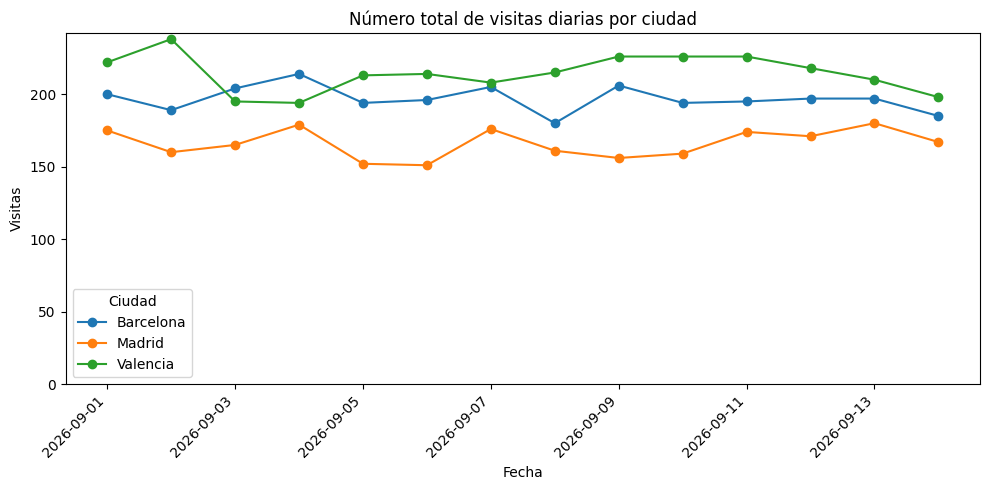

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))
visitas_diarias.plot(ax=ax, marker='o')
ax.set_title('Número total de visitas diarias por ciudad')
ax.set_xlabel('Fecha')
ax.set_ylabel('Visitas')
ax.set_ylim(bottom=0)
ax.legend(title='Ciudad')
plt.xticks(rotation=45, ha='right')
fig.tight_layout()
fig.savefig(SALIDAS / 'visitas_diarias.png', dpi=150)
plt.show()

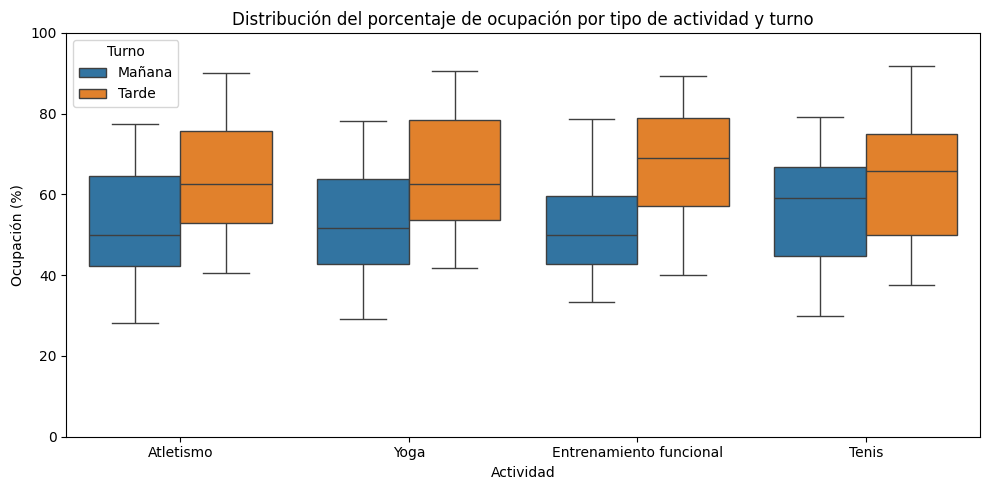

In [35]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=preparada, x='actividad', y='ocupacion_pct', hue='turno', ax=ax)
ax.set_title('Distribución del porcentaje de ocupación por tipo de actividad y turno')
ax.set_xlabel('Actividad')
ax.set_ylabel('Ocupación (%)')
ax.set_ylim(0, 100)
ax.legend(title='Turno')
fig.tight_layout()
fig.savefig(SALIDAS / 'ocupacion_actividad.png', dpi=150)
plt.show()

**Respuesta:** escribe una observación descriptiva de cada gráfico. Distingue visitas totales y porcentaje de ocupación. Explica por qué estos datos sintéticos no permiten atribuir a la meteorología cambios en la asistencia.


*   En el primer gráfico, referente a las visitas totales diarias por ciudad, podemos observar que Valencia registra en general más visitas diarias (línea verde), Madrid la que menos (línea naranja) y Barcelona se encuentra en una posición intermedia (línea azul) aunque con ciertas variaciones.
*   En el segundo gráfico, referente a la distribución del porcentaje de ocupación por tipo de actividad y turno, podemos observar que los turnos de tarde (en naranja) presentan una ocupación porcentual generalmente mayor en las cuatro actividades.

Por último, como los datos son sintéticos y no se ha realizado un análisis causal que tenga en cuenta otros factores que no sean los meteorológicos, no podemos atribuir los cambios observados únicamente a dichas condiciones meteorológicas.



## 6. Revisar código con IA y guardar resultados
### Revisar una propuesta
Un asistente propone unir la meteorología solo mediante `ciudad`:
```python
preparada = actividad_original.merge(centros, on='centro_id', how='left')
preparada = preparada.merge(meteo, on='ciudad', how='left')
```
Lee la propuesta y compárala con T5. ¿Qué ocurre cuando una ciudad tiene 14 días meteorológicos? Explica por qué añadir `fecha` a la clave cambia el resultado. Puedes comprobarlo en una tabla temporal sin sustituir `preparada`.

Después, solicita a la IA que revise una función o agrupación concreta. Dale el objetivo, las columnas y el fragmento. Comprueba su sugerencia antes de incorporarla.

| Decisión | Consulta y sugerencia | Qué aceptaste o cambiaste | Comprobación y resultado |
|---|---|---|---|
| 1 | Revisión de T5: ¿bastaría con unir por ejemplo por ciudad? La IA nos explicó que esto haría que cada sesión se repitiera 14 veces, al asociarse con todos los días de esa ciudad. | Decidimos mantener la unión por centro_id y la meteorología por ciudad y fecha. | Una vez hecho, comprobamos que al unir las tablas se mantuvieron las 504 sesiones originales, sin duplicar filas. |
| 2 | Revisión de T7: ¿cómo podríamos sumar visitas por nombre y promediar  ocupacion_pct por actividad y turno?. La IA nos sugirió `groupby` con `sum` y `mean`, respectivamente. | Decidimos aceptar ambas sugerencias, distinguiendo visitas totales de ocupación media por sesión. | Comprobamos que la suma de visitas por centro coincidía con el total original (8085) y que obtuvimos ocho valores de ocupación media, uno por cada combinación de actividad y turno. |

No hace falta entregar conversaciones completas.

### Exportar resultados
Se guarda la actividad enriquecida, la meteorología por ciudad-día, los resúmenes y los dos gráficos. Las entradas permanecen separadas.

In [ ]:
preparada.to_csv(SALIDAS / 'actividad_preparada.csv', index=False)
meteo.to_csv(SALIDAS / 'meteo_diaria.csv', index=False)
resumen.to_csv(SALIDAS / 'resumen_centros.csv')
ocupacion_por_turno.to_csv(SALIDAS / 'ocupacion_por_turno.csv')
visitas_diarias.to_csv(SALIDAS / 'visitas_diarias.csv')

In [ ]:
ficha = {
    'actividad': 'Datos sintéticos docentes MABA',
    'meteorologia': 'API histórica de Open-Meteo',
    'periodo': ['2026-09-01', '2026-09-14'],
    'ciudades': list(ciudades_api),
    'variables': 'temperature_2m_max,temperature_2m_min,precipitation_sum'
}
with open(SALIDAS / 'fuentes.json', 'w', encoding='utf-8') as archivo:
    json.dump(ficha, archivo, ensure_ascii=False, indent=2)

### Comprobación de resultados
Las uniones deben conservar las 504 sesiones. La suma de visitas debe coincidir en la entrada, la tabla preparada y los resúmenes. Revisa los títulos y las unidades de los gráficos y la fuente realmente utilizada.

In [ ]:
print('Sesiones de entrada:', len(actividad_original))
print('Sesiones tras unir:', len(preparada))
print('Visitas de entrada:', actividad_original['visitas'].sum())
print('Visitas tras unir:', preparada['visitas'].sum())
print('Visitas del resumen:', resumen.sum())
print('Visitas de la tabla diaria:', visitas_diarias.sum().sum())

In [ ]:
import shutil

shutil.make_archive('resultados_centros', 'zip', SALIDAS)
files.download('resultados_centros.zip')

### README y versión final en GitHub
Completa la plantilla `README_plantilla.md` en el README de tu repositorio. Describe las fuentes, las entradas, los pasos para cargar archivos en Colab y las salidas. Registra las dos decisiones sobre IA.

Guarda el notebook desde Colab en **el mismo repositorio, rama y ruta `practica_centros.ipynb`** de la versión inicial. Usa un mensaje como `Completa funciones, uniones y resultados`. En GitHub, localiza el historial y explica una diferencia entre las dos versiones.

Guardar en Drive no actualiza GitHub. Guardar en GitHub tampoco incorpora los CSV de ejecución. Descarga el ZIP y adjúntalo a la entrega. Para reproducir el proyecto desde el repositorio, sube también el CSV y el Excel de entrada desde la web a una carpeta `datos`.

**Entrega:** enlace al repositorio, enlace al commit final y ZIP de resultados.

## 7. Comprobación individual final, sin IA
1. Explica una modificación de código, su propósito y cómo la comprobaste.

En el ejercicio R1 modificamos la función calcular_ocupacion, sustituyendo `print` por `return`. Con esto lo que conseguimos es que la función devuelva el porcentaje de ocupación calculado, en lugar de limitarse a imprimirlo por pantalla. Para comprobar que funcionaba correctamente, ejecutamos `calcular_ocupacion(15, 20)` y obtuvimos `75`, que era el resultado esperado.

2. ¿Por qué tenemos 504 sesiones, 6 centros y 42 filas meteorológicas? ¿Qué representa una fila en cada caso?

En primer lugar, tenemos 504 sesiones porque cada fila de la tabla de actividad representa una sesión deportiva diferente. Por otro lado, el catálogo contiene 6 filas, una por cada centro deportivo. Y, por último, la meteorología tiene 42 filas porque recoge los datos meteorológicos de 3 ciudades durante 14 días, de manera que cada fila representa las condiciones meteorológicas de una ciudad en un día concreto.

3. Explica las claves de las dos uniones. ¿Por qué no basta con unir meteorología por ciudad?

La primera unión utiliza centro_id para añadir a cada sesión deportiva la información del centro donde se celebra. La segunda utiliza ciudad y fecha para añadir los datos meteorológicos correspondientes. Como ya hemos explicado, no basta con unir solo por ciudad porque cada sesión se asociaría con los datos meteorológicos de los 14 días de esa ciudad, apareciendo repetida 14 veces. Por tanto, necesitamos ambas columnas para asignar a cada sesión la meteorología del lugar y día en que se celebró.

4. ¿Qué devuelven `calcular_ocupacion(18, 24)` y `clasificar_ocupacion(80)`? Explica cómo se obtienen.

La función `calcular_ocupacion(18, 24)` devuelve `75`, ya que dividimos el número de visitas (18) entre el número de plazas (24) y luego multiplicamos por 100. Por otro lado, `clasificar_ocupacion(80)` devuelve `'Alta'`, porque la función clasifica como alta cualquier ocupación igual o superior al 80%.

5. ¿Qué cambiarías en T7 para obtener visitas totales por turno?

Para lograr eso, cambiaríamos la agrupación por nombre del centro por una agrupación por turno, sin cambiar la suma de visitas. Por tanto, quedaría así: `preparada.groupby('turno')['visitas'].sum()`.

**Nombre y respuesta individual:** …

## Referencias
- [Open-Meteo: API histórica y variables](https://open-meteo.com/en/docs/historical-weather-api).
- [Requests: peticiones y respuestas](https://requests.readthedocs.io/en/latest/user/quickstart/).
- [pandas: merge](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html).
- [SciPy: rango intercuartílico](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.iqr.html).
- [Colab: archivos y entorno temporal](https://research.google.com/colaboratory/faq.html).

Los datos meteorológicos pueden revisarse en el servicio. Se comprueban estructura, fechas y unidades, sin exigir valores meteorológicos inmutables.